In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import pickle
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import subprocess
import sys
from pathlib import Path

# --- Custom imports ---
from Helpers import *   # Contains utility functions for data processing and plotting

# Configure matplotlib for consistent plots
plt.style.use("seaborn-v0_8-whitegrid")

In [2]:
def load_data(file_path):
    """
    Loads a two-column Parquet file and converts it back into a Python dictionary.
    """
    # 1. Read the Parquet file into a DataFrame
    df = pd.read_parquet(file_path)
    
    # 2. Zip the 'key' and 'value' columns together and convert to a dict
    return dict(zip(df['key'], df['value']))

In [4]:
# --- Load data files ---
ROOT_PATH = "/data/pgangwar/vaccinescout/data/"
DATA_PATH = ROOT_PATH + "final_df.parquet"

current_dict = ROOT_PATH + "current_id_to_seq.parquet"
dist_parquet = ROOT_PATH + "pairwise_dist.parquet"
curr_seq_mut_sites_parquet = ROOT_PATH + "current_sequence_mutation_sites.parquet"

final_df = pd.read_parquet(DATA_PATH)

id_to_seq = load_data(ROOT_PATH + "sequence_dict.parquet")

refSeq = getReference(ROOT_PATH + 'ref_spike_genome.fa')

vaccine_df = pd.read_pickle(ROOT_PATH + 'vaccine_recommendations.pkl')

ver = 'Jan_4_24'

pyro_df = pd.read_pickle(ROOT_PATH + f'pyro_ver/{ver}/PyroSpike.pkl')

In [5]:
# --- Define cutoff date ---
cutoff_date = "2022-06-01"

d = 30

# --- Split dataframe into circulating and future segments ---
current_df, future_df = split_circulating_and_future(
    final_df,
    cutoff_date_str=cutoff_date,
    left_buffer_days=4,
    right_buffer_days=4,
    circulation_months=None,
    circulation_days=d,
    future_months=12,
    future_days=None
)

# --- Define windows for slicing future data ---
#disjoint_windows = ['3M_1', '3M_2', '3M_3', '3M_4']
disjoint_windows = ['6M_1', '6M_2']

# --- Perform slicing ---
future_slices = slice_by_disjoint_windows(future_df, disjoint_windows)

# --- Summary output ---
print(f"future_slices slices: {list(future_slices.keys())}")

future_slices slices: ['6M_1', '6M_2']


In [6]:
# --- Group by sequence ID and count tips ---
current_seq_df = (
    current_df.groupby('Sequence_ID')
    .size()
    .reset_index(name='Tip_Count')
    .sort_values(by='Tip_Count', ascending=False)
    .reset_index(drop=True)
)

min_tip_count = 5
current_seq_df = (
    current_seq_df[current_seq_df['Tip_Count'] >= min_tip_count]
    .reset_index(drop=True)
)

future_seq_dfs = {
    k: (
        v.groupby('Sequence_ID')
        .size()
        .reset_index(name='Tip_Count')
        .sort_values(by='Tip_Count', ascending=False)
        .reset_index(drop=True)
    )
    for k, v in future_slices.items()
}

print("Total Tips:", len(current_df))
print("Total Spikes:", len(current_seq_df))

Total Tips: 483849
Total Spikes: 2386


In [7]:
# -- Process Sequence Weights --- 
current_seq_df["Weight"] = current_seq_df["Tip_Count"] / current_seq_df["Tip_Count"].sum()

for interval, df in future_seq_dfs.items():
    # Calculate the normalized weight (sums to 1)
    df["Weight"] = df["Tip_Count"] / df["Tip_Count"].sum()

In [ ]:
# Calculate fitness with CoVFit

_notebook_dir = Path.cwd()
if not (_notebook_dir / "scout_selection.ipynb").exists():
    _notebook_dir = _notebook_dir / "scripts"
COVFIT_DIR = (_notebook_dir / ".." / "CoVFit_CLI").resolve()
fasta_path = Path(ROOT_PATH) / "vaccine_scout_current_seq_df.fasta"

missing_ids = []
n_written = 0
with open(fasta_path, "w") as fasta_file:
    for seq_id in current_seq_df["Sequence_ID"]:
        seq = id_to_seq.get(seq_id)
        if seq is None:
            missing_ids.append(seq_id)
            continue
        fasta_file.write(f">{seq_id}\n{seq}\n")
        n_written += 1

print(f"Wrote {n_written:,} sequences to {fasta_path}")
if missing_ids:
    print(f"Warning: {len(missing_ids):,} Sequence_IDs missing from id_to_seq")

# --- Run CoVFit CLI ---
covfit_outdir = Path(ROOT_PATH) / cutoff_date / "current_covfit"
covfit_outdir.mkdir(parents=True, exist_ok=True)

covfit_cmd = [
    "./covfit_cli",
    "-i",
    str(fasta_path),
    "-o",
    str(covfit_outdir),
    "-g",
    "-b",
    "16",
    "-f",
    "3",
    "-d",
]
print("Running:", " ".join(covfit_cmd))

result = subprocess.run(
    covfit_cmd,
    cwd=str(COVFIT_DIR),
    capture_output=True,
    text=True,
)
print(result.stdout)
if result.stderr:
    print(result.stderr)
if result.returncode != 0:
    raise RuntimeError(f"covfit_cli failed with exit code {result.returncode}")

covfit_output = covfit_outdir / "CoVFit_Predictions_fold_3.tsv"
print(f"CoVFit predictions written to {covfit_output}")

In [8]:
# --- Load CoVFit fitness scores ---
FITNESS_COLUMN = "fitness_mean"

covfit_output = covfit_outdir / "CoVFit_Predictions_fold_3.tsv"
covfit_score_df = pd.read_csv(covfit_output, sep="\t")
covfit_score_df = covfit_score_df.rename(columns={"seq_name": "Sequence_ID"})

if FITNESS_COLUMN not in covfit_score_df.columns:
    raise ValueError(
        f"Column {FITNESS_COLUMN!r} not found in {covfit_output}; "
        f"available: {list(covfit_score_df.columns)}"
    )

score_map = covfit_score_df.set_index("Sequence_ID")[FITNESS_COLUMN]
missing_scores = set(current_seq_df["Sequence_ID"]) - set(score_map.index)
if missing_scores:
    raise ValueError(
        f"{len(missing_scores)} sequence(s) in current_seq_df missing {FITNESS_COLUMN!r} "
        f"in CoVFit output: {sorted(missing_scores)[:5]}"
    )

current_seq_df = current_seq_df.assign(
    **{FITNESS_COLUMN: current_seq_df["Sequence_ID"].map(score_map)}
)

print(f"Loaded {len(covfit_score_df):,} CoVFit score entries")
print(f"Added {FITNESS_COLUMN} to current_seq_df: {len(current_seq_df):,} sequences")

Loaded 2,386 CoVFit score entries
Added fitness_mean to current_seq_df: 2,386 sequences


In [9]:
# --- Compute nearest-neighbour distances within the current cohort via scripts/pairwise_dist ---
import subprocess
import pyarrow as pa
import pyarrow.parquet as pq
from pathlib import Path

cohort_dir = Path(ROOT_PATH.rstrip("/")) / cutoff_date
cohort_dir.mkdir(parents=True, exist_ok=True)

current_seq_ids = current_seq_df["Sequence_ID"].tolist()
pq.write_table(
    pa.table({
        "key":   pa.array(current_seq_ids, type=pa.string()),
        "value": pa.array([id_to_seq[sid] for sid in current_seq_ids], type=pa.string()),
    }),
    str(current_dict),
)

pairwise_dist_bin = None
_p = Path.cwd().resolve()
for _ in range(12):
    _c = _p / "scripts" / "pairwise_dist"
    if _c.is_file():
        pairwise_dist_bin = _c
        break
    if _p.parent == _p:
        break
    _p = _p.parent
if pairwise_dist_bin is None:
    pairwise_dist_bin = Path.cwd() / "scripts" / "pairwise_dist"
if not pairwise_dist_bin.is_file():
    raise FileNotFoundError(
        f"pairwise_dist not found at {pairwise_dist_bin.resolve()}. From repo root: "
        "cmake -S scripts -B scripts/build && cmake --build scripts/build -j"
    )

cmd = [
    str(pairwise_dist_bin.resolve()),
    "--parquet", str(current_dict),
    "--output", str(dist_parquet),
]
print("Running:", " ".join(cmd))
subprocess.run(cmd, check=True)

dist_df = pd.read_parquet(dist_parquet, engine="pyarrow")

Running: /home/pgangwar@AD.UCSD.EDU/FutureCoV/scripts/pairwise_dist --parquet /data/pgangwar/vaccinescout/data/current_id_to_seq.parquet --output /data/pgangwar/vaccinescout/data/pairwise_dist.parquet


pairwise_dist (compute) 2386 / 2386
pairwise_dist (write)   2386 / 2386 (5692996 rows)


wrote "/data/pgangwar/vaccinescout/data/pairwise_dist.parquet" (5692996 rows)


Preprocess Weights and Distance

In [10]:
def preprocess_for_weighted_pam_fast(
    current_seq_df: pd.DataFrame,
    dist_df: pd.DataFrame,
    *,
    use_covfit_scores: bool = False,
    covfit_score_df: pd.DataFrame = None,
    fitness_column: str = "fitness_mean",
):
    """
    Fast vectorized preprocessing for weighted PAM.

    Args:
        current_seq_df: pd.DataFrame with columns ['Sequence_ID', 'Weight']
        dist_df: pd.DataFrame with columns ['Seq_1', 'Seq_2', 'Distance']
        use_covfit_scores: If True, align per-sequence fitness from ``covfit_score_df``.
        covfit_score_df: CoVFit scores with 'Sequence_ID' and ``fitness_column``.
        fitness_column: Column in ``covfit_score_df`` to use as fitness (default: fitness_mean).

    Returns:
        dist_matrix, weights, id2idx, idx2id, fitness_scores
    """
    sequence_ids = current_seq_df['Sequence_ID'].tolist()
    id2idx = {sid: i for i, sid in enumerate(sequence_ids)}
    idx2id = {i: sid for sid, i in id2idx.items()}
    n = len(sequence_ids)

    i_indices = dist_df['Seq_1'].map(id2idx).to_numpy()
    j_indices = dist_df['Seq_2'].map(id2idx).to_numpy()
    distances = dist_df['Distance'].to_numpy(dtype=np.float32)

    dist_matrix = np.zeros((n, n), dtype=np.float32)
    dist_matrix[i_indices, j_indices] = distances

    weights_series = current_seq_df.set_index('Sequence_ID')['Weight']
    weights = np.array([weights_series[idx2id[i]] for i in range(n)], dtype=np.float32)

    if use_covfit_scores:
        if covfit_score_df is None:
            raise ValueError("covfit_score_df is required when use_covfit_scores=True")
        if fitness_column not in covfit_score_df.columns:
            raise KeyError(
                f"Column {fitness_column!r} not found in covfit_score_df; "
                f"available: {list(covfit_score_df.columns)}"
            )
        score_dict = covfit_score_df.set_index("Sequence_ID")[fitness_column].to_dict()
        missing = []
        fitness_values = []
        for i in range(n):
            sid = idx2id[i]
            if sid not in score_dict or pd.isna(score_dict[sid]):
                missing.append(sid)
            else:
                fitness_values.append(score_dict[sid])
        if missing:
            preview = ", ".join(missing[:5])
            suffix = " ..." if len(missing) > 5 else ""
            raise ValueError(
                f"{len(missing)} sequence(s) missing {fitness_column!r} in covfit_score_df: "
                f"{preview}{suffix}"
            )
        fitness_scores = np.array(fitness_values, dtype=np.float32)
        print(f"Loaded CoVFit fitness scores for {len(score_dict)} sequences.")
    else:
        fitness_scores = None
        print("Running standard unpenalized PAM (no fitness scores).")

    return dist_matrix, weights, id2idx, idx2id, fitness_scores


In [11]:
USE_COVFIT_FITNESS = True

dist_matrix, weights, id2idx, idx2id, fitness_scores = preprocess_for_weighted_pam_fast(
    current_seq_df,
    dist_df,
    use_covfit_scores=USE_COVFIT_FITNESS,
    covfit_score_df=covfit_score_df if USE_COVFIT_FITNESS else None,
)


Loaded CoVFit fitness scores for 2386 sequences.


PAM Code - Driving Function of Medoid Selection

In [12]:
# Weighted PAM: linear tip weights * e ** (beta * fitness)
# Cost minimized:
#     sum_i  w_eff[i]  *  min_m  dist_matrix[i, m]
# where w_eff = weights * e ** (beta * fitness_scores)


def exp_fitness_modifier(fitness_scores, beta):
    """Fitness modifier: e ** (beta * fitness)."""
    s_arr = np.asarray(fitness_scores, dtype=np.float32)
    return np.power(np.e, beta * s_arr)


def effective_weights(weights, fitness_scores=None, beta=None):
    """Linear tip weights times exp fitness modifier."""
    w_eff = np.asarray(weights, dtype=np.float32)
    if fitness_scores is not None and beta is not None:
        w_eff = w_eff * np.asarray(exp_fitness_modifier(fitness_scores, beta), dtype=np.float32)
    return w_eff


def weighted_pam(
    dist_matrix,
    weights,
    k,
    fitness_scores=None,
    beta=None,
    max_iter=100,
    verbose=False,
):
    """
    Weighted PAM clustering with greedy BUILD + SWAP.

    Effective cost:
        sum_i  w_eff[i] * min_m dist_matrix[i, m]
    where w_eff = weights * e ** (beta * fitness_scores)
    """
    n = dist_matrix.shape[1]
    if k <= 0 or k > n:
        raise ValueError("k must be between 1 and N")

    w_eff = effective_weights(weights, fitness_scores, beta)

    remaining = set(range(n))
    medoids = []

    total_weighted_dists = (dist_matrix * w_eff.reshape(1, -1)).sum(axis=1)
    first = int(np.argmin(total_weighted_dists))
    medoids.append(first)
    remaining.remove(first)

    def assign_to_medoids(dist_matrix, medoids):
        d_to_m = dist_matrix[:, medoids]
        nearest_idx = np.argmin(d_to_m, axis=1)
        dist1 = d_to_m[np.arange(n), nearest_idx]
        d_to_m_tmp = d_to_m.copy()
        d_to_m_tmp[np.arange(n), nearest_idx] = np.inf
        dist2 = d_to_m_tmp[np.arange(n), np.argmin(d_to_m_tmp, axis=1)]
        nearest_medoid = np.array(medoids)[nearest_idx]
        return nearest_idx, nearest_medoid, dist1, dist2

    _, _, dist1, _ = assign_to_medoids(dist_matrix, medoids)

    for _ in range(1, k):
        best_candidate = None
        best_cost = np.inf
        for c in remaining:
            new_dist = np.minimum(dist1, dist_matrix[:, c])
            cost_if_added = float(np.dot(w_eff, new_dist))
            if cost_if_added < best_cost:
                best_cost = cost_if_added
                best_candidate = c
        medoids.append(int(best_candidate))
        remaining.remove(best_candidate)
        _, _, dist1, _ = assign_to_medoids(dist_matrix, medoids)

    if verbose:
        print(f"[BUILD] Initial medoids: {medoids}")

    it = 0
    improved = True
    while improved and it < max_iter:
        improved = False
        best_delta = 0
        best_swap = None
        medoids_set = set(medoids)

        nearest_idx, nearest_medoid, dist1, dist2 = assign_to_medoids(dist_matrix, medoids)

        for m_pos, m in enumerate(medoids):
            for h in range(n):
                if h in medoids_set:
                    continue
                d_ih = dist_matrix[:, h]
                mask_better = d_ih < dist1
                delta_better = ((d_ih - dist1) * w_eff)[mask_better].sum()
                mask_owned_by_m = (nearest_medoid == m)
                mask_case2 = mask_owned_by_m & (~mask_better)
                new_dist_case2 = np.minimum(dist2, d_ih)
                delta_case2 = ((new_dist_case2 - dist1) * w_eff)[mask_case2].sum()
                delta = delta_better + delta_case2
                if delta < best_delta:
                    best_delta = delta
                    best_swap = (m_pos, h)

        if best_swap and best_delta < -1e-12:
            m_pos, h = best_swap
            medoids[m_pos] = h
            improved = True
        else:
            break
        it += 1

    _, nearest_medoid, dist1, _ = assign_to_medoids(dist_matrix, medoids)
    final_cost = float(np.dot(w_eff, dist1))
    labels = nearest_medoid.copy()

    return medoids, labels, final_cost


def future_weighted_pam(
    dist_matrix,
    weights,
    k,
    fitness_scores=None,
    beta=None,
    max_iter=100,
    verbose=False,
):
    """
    Weighted PAM where query points and candidate medoids are different sets.

    dist_matrix shape: (n_points, n_candidates)
    Medoids are indices into the candidate axis (columns).
    """
    n_points, n_candidates = dist_matrix.shape
    if k <= 0 or k > n_candidates:
        raise ValueError("k must be between 1 and the number of candidate medoids")

    w_eff = effective_weights(weights, fitness_scores, beta)

    remaining = set(range(n_candidates))
    medoids = []

    total_weighted_dists = (dist_matrix * w_eff.reshape(-1, 1)).sum(axis=0)
    first = int(np.argmin(total_weighted_dists))
    medoids.append(first)
    remaining.remove(first)

    def assign_to_medoids(dist_matrix, medoids):
        d_to_m = dist_matrix[:, medoids]
        nearest_idx = np.argmin(d_to_m, axis=1)
        dist1 = d_to_m[np.arange(n_points), nearest_idx]
        d_to_m_tmp = d_to_m.copy()
        d_to_m_tmp[np.arange(n_points), nearest_idx] = np.inf
        dist2 = d_to_m_tmp[np.arange(n_points), np.argmin(d_to_m_tmp, axis=1)]
        nearest_medoid = np.array(medoids)[nearest_idx]
        return nearest_idx, nearest_medoid, dist1, dist2

    _, _, dist1, _ = assign_to_medoids(dist_matrix, medoids)

    for _ in range(1, k):
        best_candidate = None
        best_cost = np.inf
        for c in remaining:
            new_dist = np.minimum(dist1, dist_matrix[:, c])
            cost_if_added = float(np.dot(w_eff, new_dist))
            if cost_if_added < best_cost:
                best_cost = cost_if_added
                best_candidate = c
        medoids.append(int(best_candidate))
        remaining.remove(best_candidate)
        _, _, dist1, _ = assign_to_medoids(dist_matrix, medoids)

    if verbose:
        print(f"[BUILD] Initial oracle medoids: {medoids}")

    it = 0
    improved = True
    while improved and it < max_iter:
        improved = False
        best_delta = 0
        best_swap = None
        medoids_set = set(medoids)

        nearest_idx, nearest_medoid, dist1, dist2 = assign_to_medoids(dist_matrix, medoids)

        for m_pos, m in enumerate(medoids):
            for h in range(n_candidates):
                if h in medoids_set:
                    continue
                d_ih = dist_matrix[:, h]
                mask_better = d_ih < dist1
                delta_better = ((d_ih - dist1) * w_eff)[mask_better].sum()
                mask_owned_by_m = nearest_medoid == m
                mask_case2 = mask_owned_by_m & (~mask_better)
                new_dist_case2 = np.minimum(dist2, d_ih)
                delta_case2 = ((new_dist_case2 - dist1) * w_eff)[mask_case2].sum()
                delta = delta_better + delta_case2
                if delta < best_delta:
                    best_delta = delta
                    best_swap = (m_pos, h)

        if best_swap and best_delta < -1e-12:
            m_pos, h = best_swap
            medoids[m_pos] = h
            improved = True
        else:
            break
        it += 1

    _, nearest_medoid, dist1, _ = assign_to_medoids(dist_matrix, medoids)
    final_cost = float(np.dot(w_eff, dist1))
    labels = nearest_medoid.copy()

    return medoids, labels, final_cost


In [13]:
# --- Scout PAM: linear weights, exp fitness modifier ---
BETA = 60

print(f"Config -> linear weights, exp fitness modifier, beta={BETA}")

pam_results = {}

for k in range(1, 5):  # K = 1 to 4
    print(f"\nRunning weighted PAM for K = {k}")

    medoids, labels, cost = weighted_pam(
        dist_matrix,
        weights,
        k=k,
        fitness_scores=fitness_scores,
        beta=BETA,
        max_iter=100,
        verbose=False,
    )

    medoid_ids = [idx2id[i] for i in medoids]
    label_ids = [idx2id[i] for i in labels]

    pam_results[k] = {
        'medoids': medoid_ids,
        'labels': label_ids,
        'cost': cost,
    }


Config -> linear weights, exp fitness modifier, beta=60

Running weighted PAM for K = 1

Running weighted PAM for K = 2

Running weighted PAM for K = 3

Running weighted PAM for K = 4


In [14]:
# --- Assign each medoid to lineage group(s) from lineage_spike.fasta ---

from Bio import SeqIO
from datetime import datetime

LINEAGE_SPIKE_FASTA = Path(ROOT_PATH) / "lineage_spike.fasta"
MEDOID_LINEAGE_LOG = Path(ROOT_PATH) / f"medoid_lineage_assignments_linear_exp_{BETA}.log"


def spike_mutation_distance(seq_a: str, seq_b: str) -> int:
    """Number of differing amino-acid sites (Hamming distance)."""
    if len(seq_a) != len(seq_b):
        raise ValueError(
            f"Sequence length mismatch: {len(seq_a)} vs {len(seq_b)}"
        )
    return sum(a != b for a, b in zip(seq_a, seq_b))


def load_lineage_spike_groups(fasta_path: Path):
    groups = []
    for record in SeqIO.parse(str(fasta_path), "fasta"):
        lineages = record.id.split("|")
        groups.append(
            {
                "header": record.id,
                "lineages": lineages,
                "sequence": str(record.seq),
            }
        )
    return groups


def assign_medoid_lineages(medoid_seq: str, lineage_groups):
    """Return exact lineage header or closest matching group(s) with distance."""
    exact = [g for g in lineage_groups if medoid_seq == g["sequence"]]
    if exact:
        return {
            "match_type": "exact",
            "lineage_groups": [g["header"] for g in exact],
            "distance": 0,
            "closest": [(g["header"], 0) for g in exact],
        }

    distances = [
        (g["header"], spike_mutation_distance(medoid_seq, g["sequence"]))
        for g in lineage_groups
    ]
    min_dist = min(d for _, d in distances)
    closest = [(header, dist) for header, dist in distances if dist == min_dist]
    closest.sort(key=lambda x: x[0])

    return {
        "match_type": "closest",
        "lineage_groups": [header for header, _ in closest],
        "distance": min_dist,
        "closest": closest,
    }


def format_medoid_assignment_log(k, sid, assignment, missing=False):
    lines = [f"K={k}\tSequence_ID={sid}"]
    if missing:
        lines.append("  status: missing from id_to_seq")
        return lines

    lines.append(f"  match_type: {assignment['match_type']}")
    lines.append(f"  mutation_distance: {assignment['distance']}")

    if assignment["match_type"] == "exact":
        lines.append(f"  lineage_group: {assignment['lineage_groups'][0]}")
    else:
        lines.append("  closest_lineage_groups:")
        for header, dist in assignment["closest"]:
            lines.append(f"    - {header} ({dist})")

    return lines


lineage_groups = load_lineage_spike_groups(LINEAGE_SPIKE_FASTA)
medoid_lineage_assignments = {}
medoid_lineage_rows = []
log_lines = [
    "Medoid lineage assignment log",
    f"Generated: {datetime.now().isoformat(timespec='seconds')}",
    f"Lineage reference: {LINEAGE_SPIKE_FASTA}",
    f"N lineage spike groups: {len(lineage_groups)}",
    "",
]

for k, res in sorted(pam_results.items()):
    medoid_ids = res["medoids"]
    k_assignments = {}
    log_lines.append(f"=== K = {k} ===")

    for sid in medoid_ids:
        seq = id_to_seq.get(sid)
        if seq is None:
            log_lines.extend(format_medoid_assignment_log(k, sid, None, missing=True))
            medoid_lineage_rows.append(
                {
                    "K": k,
                    "Sequence_ID": sid,
                    "match_type": "missing",
                    "mutation_distance": None,
                    "lineage_group": None,
                    "closest_lineage_groups": None,
                }
            )
            continue

        assignment = assign_medoid_lineages(seq, lineage_groups)
        k_assignments[sid] = assignment
        log_lines.extend(format_medoid_assignment_log(k, sid, assignment))
        medoid_lineage_rows.append(
            {
                "K": k,
                "Sequence_ID": sid,
                "match_type": assignment["match_type"],
                "mutation_distance": assignment["distance"],
                "lineage_group": assignment["lineage_groups"][0],
                "closest_lineage_groups": "; ".join(
                    f"{header} ({dist})" for header, dist in assignment["closest"]
                ),
            }
        )

    medoid_lineage_assignments[k] = k_assignments
    log_lines.append("")

MEDOID_LINEAGE_LOG.write_text("\n".join(log_lines), encoding="utf-8")
medoid_lineage_df = pd.DataFrame(medoid_lineage_rows)

print(f"Loaded {len(lineage_groups)} lineage spike group(s) from {LINEAGE_SPIKE_FASTA}")
print(f"Wrote medoid lineage log for {len(medoid_lineage_rows)} medoid(s) to {MEDOID_LINEAGE_LOG}")

Loaded 2197 lineage spike group(s) from /data/pgangwar/vaccinescout/data/lineage_spike.fasta
Wrote medoid lineage log for 10 medoid(s) to /data/pgangwar/vaccinescout/data/medoid_lineage_assignments_linear_exp_60.log


Generate Fitness scores of Future Sequences

In [16]:
# Calculate fitness with CoVFit for future sequences 
future_seq_ids = (
    pd.concat([df[["Sequence_ID"]] for df in future_seq_dfs.values()])
    .drop_duplicates()["Sequence_ID"]
    .tolist()
)

fasta_path = Path(ROOT_PATH) / "vaccine_scout_future_seq_df.fasta"
missing_ids = []
n_written = 0
with open(fasta_path, "w") as fasta_file:
    for seq_id in future_seq_ids:
        seq = id_to_seq.get(seq_id)
        if seq is None:
            missing_ids.append(seq_id)
            continue
        fasta_file.write(f">{seq_id}\n{seq}\n")
        n_written += 1

print(f"Wrote {n_written:,} unique future sequences to {fasta_path}")
if missing_ids:
    raise ValueError(
        f"{len(missing_ids)} future Sequence_ID(s) missing from id_to_seq: "
        f"{missing_ids[:5]}{'...' if len(missing_ids) > 5 else ''}"
    )

# Use a separate output directory so current CoVFit scores are not overwritten
covfit_outdir = Path(ROOT_PATH) / cutoff_date/ "future_covfit"
covfit_outdir.mkdir(parents=True, exist_ok=True)

covfit_cmd = [
    "./covfit_cli",
    "-i",
    str(fasta_path),
    "-o",
    str(covfit_outdir),
    "-g",
    "-b",
    "16",
    "-f",
    "3",
    "-d",
]
print("Running:", " ".join(covfit_cmd))

result = subprocess.run(
    covfit_cmd,
    cwd=str(COVFIT_DIR),
    capture_output=True,
    text=True,
)
print(result.stdout)
if result.stderr:
    print(result.stderr)
if result.returncode != 0:
    raise RuntimeError(f"covfit_cli failed with exit code {result.returncode}")

covfit_output = covfit_outdir / "CoVFit_Predictions_fold_3.tsv"
print(f"CoVFit predictions written to {covfit_output}")

Wrote 123,765 unique future sequences to /data/pgangwar/vaccinescout/data/vaccine_scout_future_seq_df.fasta
Running: ./covfit_cli -i /data/pgangwar/vaccinescout/data/vaccine_scout_future_seq_df.fasta -o /data/pgangwar/vaccinescout/data/2022-06-01/future_covfit -g -b 16 -f 3 -d


KeyboardInterrupt: 

In [15]:
# Read the CoVFit scores for future sequences 

covfit_outdir = Path(ROOT_PATH) / cutoff_date/ "future_covfit"
covfit_output = covfit_outdir / "CoVFit_Predictions_fold_3.tsv"

future_covfit_score_df = pd.read_csv(covfit_output, sep="\t")
future_covfit_score_df = future_covfit_score_df.rename(columns={"seq_name": "Sequence_ID"})
if FITNESS_COLUMN not in future_covfit_score_df.columns:
    raise ValueError(
        f"Column {FITNESS_COLUMN!r} not found in {covfit_output}; "
        f"available: {list(future_covfit_score_df.columns)}"
    )

score_map = future_covfit_score_df.set_index("Sequence_ID")[FITNESS_COLUMN]

for interval, df in future_seq_dfs.items():
    missing_scores = set(df["Sequence_ID"]) - set(score_map.index)
    if missing_scores:
        raise ValueError(
            f"{len(missing_scores)} sequence(s) in {interval} missing {FITNESS_COLUMN!r} "
            f"in CoVFit output: {sorted(missing_scores)[:5]}"
        )
    future_seq_dfs[interval] = df.assign(
        **{FITNESS_COLUMN: df["Sequence_ID"].map(score_map)}
    )
    print(
        f"Added {FITNESS_COLUMN} to {interval}: "
        f"{len(future_seq_dfs[interval]):,} sequences"
    )

print(f"Loaded {len(future_covfit_score_df):,} CoVFit score entries for future sequences")

Added fitness_mean to 6M_1: 69,836 sequences
Added fitness_mean to 6M_2: 64,606 sequences
Loaded 123,765 CoVFit score entries for future sequences


FDA Recommended Strains

In [24]:
# --- Load clade sequences for FDA-recommended strains ---
vaccine_df = vaccine_df.rename(columns={'clade': 'Sequence_ID'})
clade_to_seq = dict(zip(vaccine_df['Sequence_ID'], vaccine_df['mutated_sequence']))

# --- CoVFit fitness for vaccine strains ---
vaccine_fasta_path = Path(ROOT_PATH) / "vaccine_scout_strains.fasta"
with open(vaccine_fasta_path, "w") as fasta_file:
    for strain, seq in clade_to_seq.items():
        fasta_file.write(f">{strain}\n{seq}\n")

vaccine_covfit_outdir = Path(ROOT_PATH) / cutoff_date / "vaccine_covfit"
vaccine_covfit_outdir.mkdir(parents=True, exist_ok=True)

vaccine_covfit_cmd = [
    "./covfit_cli",
    "-i",
    str(vaccine_fasta_path),
    "-o",
    str(vaccine_covfit_outdir),
    "-g",
    "-b",
    "16",
    "-f",
    "3",
    "-d",
]
print("Running:", " ".join(vaccine_covfit_cmd))

vaccine_covfit_result = subprocess.run(
    vaccine_covfit_cmd,
    cwd=str(COVFIT_DIR),
    capture_output=True,
    text=True,
)
print(vaccine_covfit_result.stdout)
if vaccine_covfit_result.stderr:
    print(vaccine_covfit_result.stderr)
if vaccine_covfit_result.returncode != 0:
    raise RuntimeError(f"covfit_cli failed with exit code {vaccine_covfit_result.returncode}")

vaccine_covfit_output = vaccine_covfit_outdir / "CoVFit_Predictions_fold_3.tsv"
vaccine_covfit_score_df = pd.read_csv(vaccine_covfit_output, sep="\t")
vaccine_covfit_score_df = vaccine_covfit_score_df.rename(columns={"seq_name": "Sequence_ID"})

vaccine_fitness = vaccine_covfit_score_df.set_index("Sequence_ID")[FITNESS_COLUMN].to_dict()
vaccine_df = vaccine_df.assign(
    **{FITNESS_COLUMN: vaccine_df["Sequence_ID"].map(vaccine_fitness)}
)
print(f"Loaded {len(vaccine_covfit_score_df):,} CoVFit scores for vaccine strains")

Running: ./covfit_cli -i /data/pgangwar/vaccinescout/data/vaccine_scout_strains.fasta -o /data/pgangwar/vaccinescout/data/2022-06-01/vaccine_covfit -g -b 16 -f 3 -d
Initializing model. Please wait...
Tokenizing sequences for model input
Running CoVFit
Predictions completed
Writing output to /data/pgangwar/vaccinescout/data/2022-06-01/vaccine_covfit/CoVFit_Predictions_fold_3.tsv
Done

Detected kernel version 5.4.0, which is below the recommended minimum of 5.5.0; this can cause the process to hang. It is recommended to upgrade the kernel to the minimum version or higher.

100%|██████████| 1/1 [00:00<00:00, 3158.36it/s]

Loaded 9 CoVFit scores for vaccine strains


Evaluation and Comparisons

In [17]:
# --- Oracle medoids: minimize distance to ALL future tips per slice ---
# Points: every sequence in the future slice (masked + unmasked).
# Candidates: only future sequences that are also in the current circulating pool.
ORACLE_INTERVALS = disjoint_windows


def _hamming_distance_matrix_local(sequences1, sequences2, max_block_bytes=200_000_000):
    if not sequences1 or not sequences2:
        return np.zeros((len(sequences1), len(sequences2)), dtype=np.float32)

    n1, n2 = len(sequences1), len(sequences2)
    seq_len = len(sequences1[0])
    out = np.zeros((n1, n2), dtype=np.float32)
    cand = np.array([list(s) for s in sequences2])

    elems_per_block = max(1, max_block_bytes // max(seq_len, 1))
    point_batch = max(1, min(n1, int(np.sqrt(elems_per_block))))
    cand_batch = max(1, min(n2, elems_per_block // point_batch))

    for c0 in range(0, n2, cand_batch):
        c1 = min(c0 + cand_batch, n2)
        cand_chunk = cand[c0:c1]
        for p0 in range(0, n1, point_batch):
            p1 = min(p0 + point_batch, n1)
            point_chunk = np.array([list(s) for s in sequences1[p0:p1]])
            out[p0:p1, c0:c1] = np.sum(
                point_chunk[:, None, :] != cand_chunk[None, :, :],
                axis=2,
            )
    return out


oracle_pam_results = {}

for oracle_interval in ORACLE_INTERVALS:
    oracle_future_df = future_seq_dfs[oracle_interval].copy().reset_index(drop=True)
    current_ids = current_seq_df["Sequence_ID"]

    point_ids = oracle_future_df["Sequence_ID"].tolist()
    point_id2row = {sid: i for i, sid in enumerate(point_ids)}

    in_current = oracle_future_df["Sequence_ID"].isin(current_ids)
    candidate_ids = oracle_future_df.loc[in_current, "Sequence_ID"].tolist()
    cand_id2idx = {sid: i for i, sid in enumerate(candidate_ids)}

    n_points = len(point_ids)
    n_candidates = len(candidate_ids)

    print(
        f"\nOracle PAM on {oracle_interval}: "
        f"{n_points:,} future points (all sequences), "
        f"{n_candidates:,} candidate medoids (future sequences currently circulating)"
    )

    if n_candidates == 0:
        raise ValueError(
            f"No overlapping sequences between {oracle_interval} and current_seq_df"
        )

    oracle_dist_matrix = np.full((n_points, n_candidates), np.nan, dtype=np.float32)

    for seq_col, other_col in [("Seq_1", "Seq_2"), ("Seq_2", "Seq_1")]:
        sub = dist_df[
            dist_df[seq_col].isin(candidate_ids)
            & dist_df[other_col].isin(candidate_ids)
        ]
        for row in sub.itertuples(index=False):
            point_id = getattr(row, seq_col)
            cand_id = getattr(row, other_col)
            i = point_id2row.get(point_id)
            j = cand_id2idx.get(cand_id)
            if i is not None and j is not None:
                oracle_dist_matrix[i, j] = row.Distance

    future_only_rows = np.flatnonzero(~in_current.to_numpy())
    if len(future_only_rows) > 0:
        future_only_seqs = [id_to_seq[point_ids[i]] for i in future_only_rows]
        candidate_seqs = [id_to_seq[sid] for sid in candidate_ids]
        hamming_block = _hamming_distance_matrix_local(
            future_only_seqs, candidate_seqs
        )
        oracle_dist_matrix[np.array(future_only_rows), :] = hamming_block

    missing_pairs = np.isnan(oracle_dist_matrix).sum()
    if missing_pairs:
        raise ValueError(
            f"Oracle distance matrix for {oracle_interval} has {missing_pairs:,} "
            "missing entries; check pairwise_dist coverage or id_to_seq for "
            "future-only sequences."
        )

    oracle_point_weights = oracle_future_df["Weight"].to_numpy(dtype=np.float32)
    oracle_point_fitness = (
        oracle_future_df[FITNESS_COLUMN].to_numpy(dtype=np.float32)
        if USE_COVFIT_FITNESS
        else None
    )

    oracle_pam_results[oracle_interval] = {}

    for k in range(1, 5):
        print(f"\nRunning oracle future_weighted_pam for {oracle_interval}, K = {k}")

        medoid_idx, labels, cost = future_weighted_pam(
            oracle_dist_matrix,
            oracle_point_weights,
            k=k,
            fitness_scores=oracle_point_fitness,
            beta=0,
            max_iter=100,
            verbose=False,
        )

        medoid_ids = [candidate_ids[i] for i in medoid_idx]

        oracle_pam_results[oracle_interval][k] = {
            "medoids": medoid_ids,
            "labels": labels,
            "cost": cost,
            "interval": oracle_interval,
            "n_points": n_points,
            "n_candidates": n_candidates,
        }

        print(f"Oracle medoids: {medoid_ids}")


Oracle PAM on 6M_1: 69,836 future points (all sequences), 2,000 candidate medoids (future sequences currently circulating)

Running oracle future_weighted_pam for 6M_1, K = 1
Oracle medoids: ['S_227403']

Running oracle future_weighted_pam for 6M_1, K = 2
Oracle medoids: ['S_227403', 'S_185188']

Running oracle future_weighted_pam for 6M_1, K = 3
Oracle medoids: ['S_227403', 'S_185188', 'S_266509']

Running oracle future_weighted_pam for 6M_1, K = 4
Oracle medoids: ['S_227403', 'S_185188', 'S_266509', 'S_253493']

Oracle PAM on 6M_2: 64,606 future points (all sequences), 278 candidate medoids (future sequences currently circulating)

Running oracle future_weighted_pam for 6M_2, K = 1
Oracle medoids: ['S_253493']

Running oracle future_weighted_pam for 6M_2, K = 2
Oracle medoids: ['S_253493', 'S_266509']

Running oracle future_weighted_pam for 6M_2, K = 3
Oracle medoids: ['S_253493', 'S_266509', 'S_256145']

Running oracle future_weighted_pam for 6M_2, K = 4
Oracle medoids: ['S_253493'

In [18]:
from tqdm import tqdm

def np_hamming_distance_matrix(sequences1, sequences2):
    """
    Computes the Hamming distance matrix between two lists/arrays of sequences.
    Assumes sequences are of the same length and contain standard characters (e.g., A, C, G, T).

    Args:
        sequences1 (list of str): The first set of sequences (rows).
        sequences2 (list of str): The second set of sequences (columns/medoids).

    Returns:
        np.ndarray: A matrix where matrix[i, j] is the Hamming distance
                    between sequences1[i] and sequences2[j].
    """
    if not sequences1 or not sequences2:
        return np.array([[]])

    # Convert lists of strings to NumPy character arrays.
    arr1 = np.array([list(s) for s in sequences1])
    arr2 = np.array([list(s) for s in sequences2])
    
    # Summing along the character axis (axis 2) gives the distance
    return np.sum(np.not_equal(arr1[:, None, :], arr2[None, :, :]), axis=2)


def fitness_adjusted_weighted_min_distance(
    distance_matrix,
    seq_fitness,
    candidate_fitness,
    weights,
    fitness_weighted=False,
    beta=None,
):
    """
    Weighted average of minimum Hamming distances.

    When fitness_weighted is False:
        contrib_i = w_i * min_j(distance_ij)

    When fitness_weighted is True (current circulating pool):
        contrib_i = w_i * e ** (beta * seq_i) * min_j(distance_ij / e ** (beta * candidate_j))
    """
    weights = np.asarray(weights, dtype=float)

    if distance_matrix.size == 0:
        return 0.0

    if fitness_weighted:
        if beta is None:
            raise ValueError("beta is required when fitness_weighted=True")
        seq_fitness_modifiers = exp_fitness_modifier(seq_fitness, beta).astype(np.float64)
        candidate_fitness_modifiers = exp_fitness_modifier(candidate_fitness, beta).astype(np.float64)
        distance_matrix = distance_matrix / candidate_fitness_modifiers.reshape(1, -1)
        weights = weights * seq_fitness_modifiers
    else:
        del seq_fitness, candidate_fitness

    min_distances = np.min(distance_matrix, axis=1)

    total_weight = np.sum(weights)
    if total_weight == 0:
        return 0.0

    return float(np.sum(min_distances * weights) / total_weight)


def evaluate_medoids_vectorized(
    medoids,
    id_to_seq_,
    future_seq_dfs,
    current_seq_df,
    fitness_column="fitness_mean",
):
    """
    Compute weighted average distance of future sequences to nearest medoid using
    vectorized operations (optimized for Hamming distance).

    Args:
        medoids: list of Sequence_IDs selected as medoids.
        id_to_seq_: dict mapping Sequence_ID -> sequence string.
        future_seq_dfs: dict of interval -> DataFrame(Sequence_ID, Weight, fitness_column).
        current_seq_df: DataFrame with medoid fitness scores keyed by Sequence_ID.
        fitness_column: Column name for CoVFit fitness scores.

    Returns:
        results: dict of interval -> weighted average min distance.
    """
    medoid_seqs = [id_to_seq_[mid] for mid in medoids]
    medoid_fitness = current_seq_df.set_index("Sequence_ID").loc[medoids, fitness_column].values

    results = {}

    for interval, df in future_seq_dfs.items():
        if df.empty:
            results[interval] = 0.0
            continue

        future_seq_ids = df["Sequence_ID"].tolist()
        future_seqs = [id_to_seq_[sid] for sid in future_seq_ids]
        weights = df["Weight"].values
        seq_fitness = df[fitness_column].values

        if not future_seqs:
            results[interval] = 0.0
            continue

        with tqdm(total=1, desc=f"Calculating Distances for {interval}") as p:
            distance_matrix = np_hamming_distance_matrix(future_seqs, medoid_seqs)
            p.update(1)

        results[interval] = fitness_adjusted_weighted_min_distance(
            distance_matrix=distance_matrix,
            seq_fitness=seq_fitness,
            candidate_fitness=medoid_fitness,
            weights=weights,
        )

    return results

In [19]:
# --- Evaluate medoids for K = 1 to 4 on Future Data ---
medoid_evaluation_results = {}
oracle_medoid_evaluation_results = {
    interval: {} for interval in ORACLE_INTERVALS
}

for k in range(1, 5):
    print(f"\nEvaluating medoids for K = {k}")
    medoid_ids = pam_results[k]["medoids"]

    weighted_avg_dists = evaluate_medoids_vectorized(
        medoids=medoid_ids,
        id_to_seq_=id_to_seq,
        future_seq_dfs=future_seq_dfs,
        current_seq_df=current_seq_df,
    )

    medoid_evaluation_results[k] = weighted_avg_dists

    for oracle_interval in ORACLE_INTERVALS:
        oracle_medoid_ids = oracle_pam_results[oracle_interval][k]["medoids"]
        oracle_medoid_evaluation_results[oracle_interval][k] = (
            evaluate_medoids_vectorized(
                medoids=oracle_medoid_ids,
                id_to_seq_=id_to_seq,
                future_seq_dfs=future_seq_dfs,
                current_seq_df=current_seq_df,
            )
        )
        print(
            f"Oracle medoids ({oracle_interval} fit): {oracle_medoid_ids}"
        )


Evaluating medoids for K = 1


Calculating Distances for 6M_2: 100%|██████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:10<00:00, 10.04s/it]


Oracle medoids (6M_1 fit): ['S_227403']


Calculating Distances for 6M_2: 100%|██████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:10<00:00, 10.27s/it]


Oracle medoids (6M_2 fit): ['S_253493']

Evaluating medoids for K = 2


...

Oracle medoids (6M_2 fit): ['S_253493', 'S_266509', 'S_256145']

Evaluating medoids for K = 4


Calculating Distances for 6M_2: 100%|██████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:10<00:00, 10.85s/it]


Oracle medoids (6M_1 fit): ['S_227403', 'S_185188', 'S_266509', 'S_253493']


Calculating Distances for 6M_2: 100%|██████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:11<00:00, 11.12s/it]

Oracle medoids (6M_2 fit): ['S_253493', 'S_266509', 'S_256145', 'S_227403']


In [20]:
from tqdm import tqdm

def evaluate_vaccines_vectorized(
    vaccines,
    vaccine_to_seq,
    id_to_seq,
    future_seq_dfs,
    vaccine_fitness,
    fitness_column="fitness_mean",
):
    """
    Compute weighted average distance of future sequences
    to the nearest vaccine candidate.

    Args:
        vaccines: list of vaccine IDs.
        vaccine_to_seq: dict mapping vaccine ID -> sequence string.
        id_to_seq: dict mapping future Sequence_ID -> sequence string.
        future_seq_dfs: dict of interval -> DataFrame(Sequence_ID, Weight, fitness_column).
        vaccine_fitness: dict mapping vaccine ID -> fitness score.
        fitness_column: Column name for CoVFit fitness scores in future_seq_dfs.

    Returns:
        results: dict of interval -> weighted average min distance.
    """
    vaccine_ids = [vid for vid in vaccines if vid in vaccine_to_seq]
    candidate_seqs = [vaccine_to_seq[vid] for vid in vaccine_ids]
    candidate_fitness = np.array([vaccine_fitness[vid] for vid in vaccine_ids], dtype=float)

    if not candidate_seqs:
        return {interval: 0.0 for interval in future_seq_dfs}

    results = {}

    for interval, df in future_seq_dfs.items():
        if df.empty:
            results[interval] = 0.0
            continue

        valid_df = df[df["Sequence_ID"].isin(id_to_seq)]

        if valid_df.empty:
            results[interval] = 0.0
            continue

        future_seq_ids = valid_df["Sequence_ID"].tolist()
        future_seqs = [id_to_seq[sid] for sid in future_seq_ids]
        weights = valid_df["Weight"].values
        seq_fitness = valid_df[fitness_column].values

        with tqdm(total=1, desc=f"Calculating Distances for {interval}") as p:
            distance_matrix = np_hamming_distance_matrix(future_seqs, candidate_seqs)
            p.update(1)

        results[interval] = fitness_adjusted_weighted_min_distance(
            distance_matrix=distance_matrix,
            seq_fitness=seq_fitness,
            candidate_fitness=candidate_fitness,
            weights=weights,
        )

    return results

In [25]:
# --- Evaluate FDA recommended strains --- 
recommended_strains = ['BA.4']
#recommended_strains = ['XBB.1.5']
#recommended_strains = ['KP.2']

vaccine_evaluation_results = {
    strain: evaluate_vaccines_vectorized(
        vaccines=[strain],
        vaccine_to_seq=clade_to_seq,
        id_to_seq=id_to_seq,
        future_seq_dfs=future_seq_dfs,
        vaccine_fitness=vaccine_fitness,
    )
    for strain in recommended_strains
}

Calculating Distances for 6M_2: 100%|██████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:09<00:00,  9.96s/it]


In [35]:
# --- Weighted average min mutation distance vs circulating sequences ---
def evaluate_on_current_vectorized(
    candidate_seqs,
    current_seq_df,
    id_to_seq,
    candidate_fitness,
    beta,
    fitness_column="fitness_mean",
):
    """
    Fitness-weighted average minimum Hamming distance from
    circulating sequences to the nearest candidate sequence.

    Uses linear weights and e ** (beta * fitness) to weight sequences and
    normalize candidate distances.
    """
    if not candidate_seqs or current_seq_df.empty:
        return 0.0

    current_ids = current_seq_df["Sequence_ID"].tolist()
    current_seqs = [id_to_seq[sid] for sid in current_ids]
    weights = current_seq_df["Weight"].values
    seq_fitness = current_seq_df[fitness_column].values
    candidate_fitness = np.asarray(candidate_fitness, dtype=float)

    distance_matrix = np_hamming_distance_matrix(current_seqs, candidate_seqs)
    return fitness_adjusted_weighted_min_distance(
        distance_matrix=distance_matrix,
        seq_fitness=seq_fitness,
        candidate_fitness=candidate_fitness,
        weights=weights,
        fitness_weighted=True,
        beta=1,
    )


medoid_fitness_map = current_seq_df.set_index("Sequence_ID")["fitness_mean"].to_dict()

for k in sorted(pam_results.keys()):
    medoid_ids = pam_results[k]["medoids"]
    medoid_seqs = [id_to_seq[mid] for mid in medoid_ids if mid in id_to_seq]
    medoid_fitness = [medoid_fitness_map[mid] for mid in medoid_ids if mid in id_to_seq]
    medoid_evaluation_results[k]["current"] = evaluate_on_current_vectorized(
        candidate_seqs=medoid_seqs,
        current_seq_df=current_seq_df,
        id_to_seq=id_to_seq,
        candidate_fitness=medoid_fitness,
        beta=BETA,
    )

    for oracle_interval in ORACLE_INTERVALS:
        oracle_medoid_evaluation_results[oracle_interval][k]["current"] = np.nan

for strain in recommended_strains:
    vaccine_evaluation_results[strain]["current"] = np.nan

print("Computed circulating-sequence distances (scout medoids only):")
for k in sorted(medoid_evaluation_results.keys()):
    print(f"  K={k}: {medoid_evaluation_results[k]['current']:.4f}")

Computed circulating-sequence distances (scout medoids only):
  K=1: 2.0293
  K=2: 1.1084
  K=3: 0.2876
  K=4: 0.2801


Mutation Distance Comparisons

In [36]:
def generate_evaluation_dataframe(
    pam_results,
    medoid_evaluation_results,
    vaccine_results,
    oracle_pam_results=None,
    oracle_medoid_evaluation_results=None,
    oracle_intervals=None,
):
    """
    Constructs a DataFrame comparing specific vaccines, K-medoid sets, and
    optional oracle medoids across the circulating pool and future temporal intervals.
    """
    print(f"Cutoff Date: {cutoff_date}")
    rows = []

    if oracle_intervals is None:
        oracle_intervals = ORACLE_INTERVALS

    slice_labels = {
        "current": "Current",
        "6M_1": "0-6 Months",
        "6M_2": "6-12 Months",
    }
    interval_display = {
        "6M_1": "0-6 Months",
        "6M_2": "6-12 Months",
    }
    column_order = [
        "CoVFit",
        "PyR0",
        "Current",
        "0-6 Months",
        "6-12 Months",
    ]

    covfit_map = current_seq_df.set_index("Sequence_ID")["fitness_mean"].to_dict()
    pyro_map = (
        current_seq_df.set_index("Sequence_ID")["Fitness_Score_pyro"].to_dict()
        if "Fitness_Score_pyro" in current_seq_df.columns
        else {}
    )

    def sorted_scores(entity_ids):
        covfit_vals = sorted(
            (covfit_map[sid] for sid in entity_ids if sid in covfit_map),
            reverse=True,
        )
        pyro_vals = sorted(
            (pyro_map[sid] for sid in entity_ids if sid in pyro_map),
            reverse=True,
        )
        return (
            ", ".join(f"{v:.5f}" for v in covfit_vals) if covfit_vals else np.nan,
            ", ".join(f"{v:.5f}" for v in pyro_vals) if pyro_vals else np.nan,
        )

    def add_interval_columns(row, intervals):
        for interval_key in ["current", "6M_1", "6M_2"]:
            if interval_key in intervals:
                row[slice_labels[interval_key]] = round(intervals[interval_key], 4)
        return row

    # 1. Process Individual Vaccines (e.g., BA.4, BA.5)
    for vaccine_id, intervals in vaccine_results.items():
        row = {"Entity": f"Vaccine: {vaccine_id}"}
        row = add_interval_columns(row, intervals)
        rows.append(row)

    has_oracle = (
        oracle_pam_results is not None
        and oracle_medoid_evaluation_results is not None
    )

    # 2. Process K-Medoid Sets (scout, then oracle per slice for each K)
    for k in sorted(medoid_evaluation_results.keys()):
        medoid_ids = pam_results[k].get("medoids", [])
        medoid_str = ", ".join(map(str, medoid_ids))

        row = {"Entity": f"K={k} Medoids ({medoid_str})"}
        row["CoVFit"], row["PyR0"] = sorted_scores(medoid_ids)
        row = add_interval_columns(row, medoid_evaluation_results[k])
        rows.append(row)

        if has_oracle:
            for oracle_interval in oracle_intervals:
                interval_results = oracle_medoid_evaluation_results.get(
                    oracle_interval, {}
                )
                interval_pam = oracle_pam_results.get(oracle_interval, {})
                if k not in interval_results or k not in interval_pam:
                    continue

                oracle_medoid_ids = interval_pam[k].get("medoids", [])
                oracle_medoid_str = ", ".join(map(str, oracle_medoid_ids))
                oracle_label = interval_display.get(
                    oracle_interval, oracle_interval
                )

                row = {
                    "Entity": (
                        f"Oracle K={k} Medoids ({oracle_medoid_str}) "
                        f"[fit: {oracle_label}]"
                    )
                }
                row["CoVFit"], row["PyR0"] = sorted_scores(oracle_medoid_ids)
                row = add_interval_columns(row, interval_results[k])
                rows.append(row)

    df = pd.DataFrame(rows)
    if not df.empty:
        df.set_index("Entity", inplace=True)
        df = df[[col for col in column_order if col in df.columns]]

    return df


evaluation_df = generate_evaluation_dataframe(
    pam_results,
    medoid_evaluation_results,
    vaccine_evaluation_results,
    oracle_pam_results=oracle_pam_results,
    oracle_medoid_evaluation_results=oracle_medoid_evaluation_results,
    oracle_intervals=ORACLE_INTERVALS,
)

print(evaluation_df.to_string())

Cutoff Date: 2022-06-01
                                                                                                            CoVFit                                PyR0  Current  0-6 Months  6-12 Months
Entity                                                                                                                                                                                  
Vaccine: BA.4                                                                                                  NaN                                 NaN      NaN      1.6253       9.3282
K=1 Medoids (S_227403)                                                                                     0.53196                             4.42300   2.0293      1.6253       9.3282
Oracle K=1 Medoids (S_227403) [fit: 0-6 Months]                                                            0.53196                             4.42300      NaN      1.6253       9.3282
Oracle K=1 Medoids (S_253493) [fit: 6-12 Months]   

Plotting Performance

In [37]:
def plot_medoid_performance(medoid_evaluation_results, cutoff_date):
    """
    Plots medoid coverage for current sequences and future interval distances.
    
    Args:
        medoid_evaluation_results: dict[k][interval] -> numeric avg distance
        cutoff_date: str for plot title metadata
    """
    # Publication Style Settings (Nature-level)
    plt.rcParams.update({
        'font.size': 12,
        'axes.labelsize': 14,
        'axes.titlesize': 14,
        'xtick.labelsize': 13,
        'ytick.labelsize': 13,
        'legend.fontsize': 10
    })

    plt.figure(figsize=(8, 6))
    
    # Extract K values (X-axis) and sort them
    k_values = sorted(medoid_evaluation_results.keys())
    
    # Mapping for interval labels
    slice_labels = {
        "current": "Current Sequences",
        "6M_1": "0-6 Months",
        "6M_2": "6-12 Months"
    }
    
    # 1. Plot the Current Interval (Black dashed line to distinguish from future)
    if "current" in medoid_evaluation_results[k_values[0]]:
        current_vals = [medoid_evaluation_results[k]["current"] for k in k_values]
        plt.plot(k_values, current_vals, marker='o', color='black', linestyle='--', 
                 label=slice_labels["current"], zorder=5, alpha=0.75)
        
        # Annotations for current (placed slightly below to avoid overlap)
        for xi, yi in zip(k_values, current_vals):
            plt.text(xi, yi - 0.25, f"{yi:.4f}", color='black', ha='center', va='top', fontsize=10)

    # 2. Plot the Future Intervals
    # Get all slice keys from the first available K, excluding "current"
    interval_keys = [key for key in next(iter(medoid_evaluation_results.values())).keys() if key != "current"]
    colors = sns.color_palette("colorblind", n_colors=len(interval_keys))

    for idx, interval_key in enumerate(interval_keys):
        y_vals = [medoid_evaluation_results[k][interval_key] for k in k_values]
        label = slice_labels.get(interval_key, interval_key)
        
        plt.plot(k_values, y_vals, marker='x', color=colors[idx], 
                 label=label, alpha=1)
        
        # Add annotations for future intervals (placed slightly above)
        for xi, yi in zip(k_values, y_vals):
            plt.text(xi, yi + 0.25, f"{yi:.4f}", color=colors[idx], ha='center', va='bottom', fontsize=10, fontweight='bold')

    # Formatting
    plt.title(f"Cutoff Date: {cutoff_date}")
    plt.xlabel("Number of Medoids ($K$)")
    plt.ylabel("Average Minimum Mutation Distance")
    
    plt.xticks(k_values)
    plt.grid(True, linestyle="--", alpha=0.3)
    plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=5, frameon=True, borderaxespad=0.)
    
    # Despine for cleaner look
    sns.despine()
    
    plt.tight_layout()
    #plt.savefig(f"/home/pgangwar@AD.UCSD.EDU/FutureCoV/{cutoff_date}/scout_performance.svg", format='svg', bbox_inches='tight')
    plt.show()

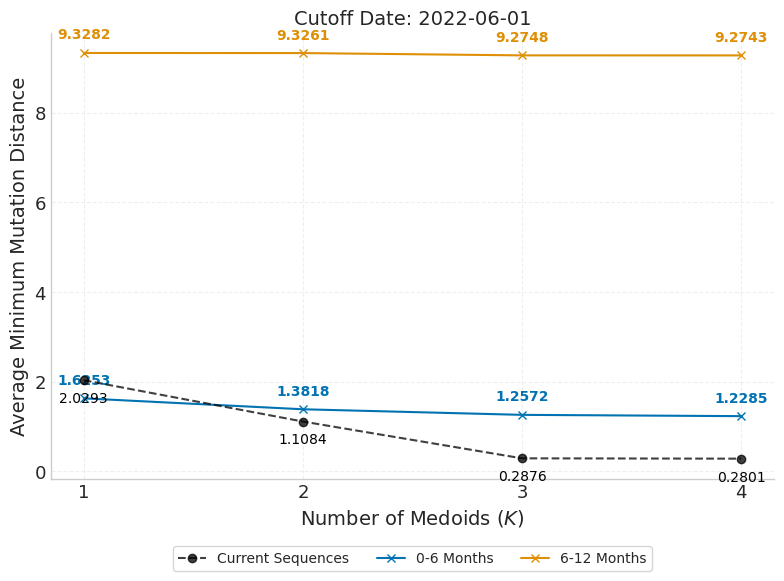

In [38]:
plot_medoid_performance(
    medoid_evaluation_results=medoid_evaluation_results,
    cutoff_date=cutoff_date
)

Distance Comparison

In [39]:
def calculate_and_print_vaccine_medoid_distances(recommended_strains, clade_to_seq, pam_results, id_to_seq):
    """
    Calculates Hamming distance between each vaccine and each individual medoid within each K set.
    Prints results in a hierarchical structured format.
    """
    
    # Helper for single-pair Hamming distance
    def get_hamming(s1, s2):
        if len(s1) != len(s2):
            return None
        return sum(c1 != c2 for c1, c2 in zip(s1, s2))

    print(f"{'='*60}")
    print(f"{'VACCINE VS MEDOID HAMMING DISTANCES':^60}")
    print(f"{'='*60}\n")

    for k in sorted(pam_results.keys()):
        medoid_ids = pam_results[k].get('medoids', [])
        print(f"Configuration: K = {k}")
        print(f"{'-'*30}")

        for m_id in medoid_ids:
            # Retrieve medoid sequence
            m_seq = id_to_seq.get(m_id)
            if m_seq is None:
                print(f"  [!] Medoid {m_id} not found in id_to_seq.")
                continue

            print(f"  Medoid ID: {m_id}")
            
            for vaccine_id in recommended_strains:
                # Retrieve vaccine sequence
                v_seq = clade_to_seq.get(vaccine_id)
                if v_seq is None:
                    print(f"    - vs {vaccine_id:.<15} [!] Not found in clade_to_seq")
                    continue
                
                dist = get_hamming(v_seq, m_seq)
                
                if dist is None:
                    print(f"    - vs {vaccine_id:.<15} Error: Length Mismatch")
                else:
                    print(f"    - vs {vaccine_id:.<15} Distance: {dist}")
            print() # Spacer between medoids
        print(f"{'='*60}\n")

# Usage Call:
calculate_and_print_vaccine_medoid_distances(
    recommended_strains= recommended_strains,
    clade_to_seq=clade_to_seq,
    pam_results=pam_results,
    id_to_seq=id_to_seq
)

            VACCINE VS MEDOID HAMMING DISTANCES             

Configuration: K = 1
------------------------------
  Medoid ID: S_227403
    - vs BA.4........... Distance: 0


Configuration: K = 2
------------------------------
  Medoid ID: S_227403
    - vs BA.4........... Distance: 0

  Medoid ID: S_230010
    - vs BA.4........... Distance: 4


Configuration: K = 3
------------------------------
  Medoid ID: S_227403
    - vs BA.4........... Distance: 0

  Medoid ID: S_230010
    - vs BA.4........... Distance: 4

  Medoid ID: S_185188
    - vs BA.4........... Distance: 3


Configuration: K = 4
------------------------------
  Medoid ID: S_227403
    - vs BA.4........... Distance: 0

  Medoid ID: S_230010
    - vs BA.4........... Distance: 4

  Medoid ID: S_185188
    - vs BA.4........... Distance: 3

  Medoid ID: S_242984
    - vs BA.4........... Distance: 1




PyR0 Fitness Score Comparisons

In [40]:
mutation_score_dict_pyro = (
    pyro_df.set_index("mutation")["R / R_A"].to_dict()
)

print(f"Loaded {len(mutation_score_dict_pyro)} PyR₀ mutation scores")

Loaded 2478 PyR₀ mutation scores


In [41]:
# --- Add mutation information to current sequences ---
current_seq_df = add_mutations_column(current_seq_df, id_to_seq, refSeq)

# --- Compute PyR₀ fitness scores ---
current_seq_df = add_fitness_scores_pyro(current_seq_df, mutation_score_dict_pyro)

In [42]:
# --- Add mutation information to current sequences ---
vaccine_df = add_mutations_column(vaccine_df, clade_to_seq, refSeq)

# --- Compute PyR₀ fitness scores ---
vaccine_df = add_fitness_scores_pyro(vaccine_df, mutation_score_dict_pyro)

In [43]:
def print_fitness_scores(pam_results, recommended_strains, current_seq_df, vaccine_df):
    """
    Look up and print fitness_score_pyro for medoids and vaccines.
    Uses Sequence_ID as the key for lookup.
    """
    
    # Pre-index DataFrames for O(1) lookup performance
    # Handling cases where IDs might be missing
    fitness_map_medoids = current_seq_df.set_index('Sequence_ID')['Fitness_Score_pyro'].to_dict()
    fitness_map_vaccines = vaccine_df.set_index('Sequence_ID')['Fitness_Score_pyro'].to_dict()

    print(f"{'='*60}")
    print(f"{'FITNESS SCORE (PYRO) EVALUATION':^60}")
    print(f"{'='*60}\n")

    # 1. Print Vaccine Fitness Scores
    print("VACCINE STRAIN SCORES")
    print(f"{'-'*30}")
    for strain in recommended_strains:
        score = fitness_map_vaccines.get(strain, "N/A (Not Found)")
        score_val = f"{score:.5f}" if isinstance(score, float) else score
        print(f"  {strain:.<20} Score: {score_val}")
    print()

    # 2. Print Medoid Fitness Scores per K
    for k in sorted(pam_results.keys()):
        medoid_ids = pam_results[k].get('medoids', [])
        print(f"MEDOIDS FOR K = {k}")
        print(f"{'-'*30}")
        
        for m_id in medoid_ids:
            score = fitness_map_medoids.get(m_id, "N/A (Not Found)")
            score_val = f"{score:.5f}" if isinstance(score, float) else score
            print(f"  ID: {m_id:.<18} Score: {score_val}")
        print()

    # 3. Print Oracle Medoid Fitness Scores per slice and K
    if "oracle_pam_results" in globals():
        covfit_map = current_seq_df.set_index("Sequence_ID")["fitness_mean"].to_dict()
        for oracle_interval in ORACLE_INTERVALS:
            interval_results = oracle_pam_results.get(oracle_interval, {})
            for k in sorted(interval_results.keys()):
                medoid_ids = interval_results[k].get("medoids", [])
                oracle_label = {
                    "6M_1": "0-6 Months",
                    "6M_2": "6-12 Months",
                }.get(oracle_interval, oracle_interval)
                print(f"ORACLE MEDOIDS FOR K = {k} [fit: {oracle_label}]")
                print(f"{'-'*30}")
                for m_id in medoid_ids:
                    pyro_score = fitness_map_medoids.get(m_id, "N/A (Not Found)")
                    pyro_val = (
                        f"{pyro_score:.5f}"
                        if isinstance(pyro_score, float)
                        else pyro_score
                    )
                    covfit_score = covfit_map.get(m_id, "N/A (Not Found)")
                    covfit_val = (
                        f"{covfit_score:.5f}"
                        if isinstance(covfit_score, float)
                        else covfit_score
                    )
                    print(
                        f"  ID: {m_id:.<18} PyR0: {pyro_val}  CoVFit: {covfit_val}"
                    )
                print()

    print(f"{'='*60}")

print_fitness_scores(pam_results, recommended_strains, current_seq_df, vaccine_df)

              FITNESS SCORE (PYRO) EVALUATION               

VACCINE STRAIN SCORES
------------------------------
  BA.4................ Score: 4.42300

MEDOIDS FOR K = 1
------------------------------
  ID: S_227403.......... Score: 4.42300

MEDOIDS FOR K = 2
------------------------------
  ID: S_227403.......... Score: 4.42300
  ID: S_230010.......... Score: 4.08895

MEDOIDS FOR K = 3
------------------------------
  ID: S_227403.......... Score: 4.42300
  ID: S_230010.......... Score: 4.08895
  ID: S_185188.......... Score: 4.05192

MEDOIDS FOR K = 4
------------------------------
  ID: S_227403.......... Score: 4.42300
  ID: S_230010.......... Score: 4.08895
  ID: S_185188.......... Score: 4.05192
  ID: S_242984.......... Score: 4.42690

ORACLE MEDOIDS FOR K = 1 [fit: 0-6 Months]
------------------------------
  ID: S_227403.......... PyR0: 4.42300  CoVFit: 0.53196

ORACLE MEDOIDS FOR K = 2 [fit: 0-6 Months]
------------------------------
  ID: S_227403.......... PyR0: 4.42300  C